# Paper 29: Denoising Diffusion Probabilistic Models (DDPM)
**Authors**: Jonathan Ho, Ajay Jain, Pieter Abbeel (UC Berkeley - NeurIPS 2020)

---

## 1. The Core Breakdown: The Generative Learning Trilemma
Before 2020, generative models faced an intractable compromise: GANs suffered from mode collapse and training instability; VAEs and Flows suffered from blurry samples or restrictive invertibility; Autoregressive models suffered from slow $O(N)$ serial generation. DDPM resolves this by framing generation as the **time-reversal of a thermodynamic diffusion process**.

## 2. Closed-Form Forward Diffusion ($q$-Sampling)
Given data $x_0$, the forward process adds Gaussian noise according to variance schedule $\beta_1, \dots, \beta_T$:
$$q(x_t | x_0) = \mathcal{N}\left(x_t; \sqrt{\bar{\alpha}_t} x_0, (1 - \bar{\alpha}_t) I\right)$$
$$x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1 - \bar{\alpha}_t} \epsilon, \quad \epsilon \sim \mathcal{N}(0, I)$$
where $\alpha_t = 1 - \beta_t$ and $\bar{\alpha}_t = \prod_{s=1}^t \alpha_s$. This allows jumping to any timestep $t$ in $O(1)$!

## 3. Simplified Training Objective ($L_{\text{simple}}$)
Instead of predicting $x_0$ directly, the U-Net $\epsilon_\theta(x_t, t)$ predicts the injected noise vector $\epsilon$:
$$L_{\text{simple}}(\theta) = \mathbb{E}_{t, x_0, \epsilon} \left[ \left\| \epsilon - \epsilon_\theta\left(\sqrt{\bar{\alpha}_t} x_0 + \sqrt{1 - \bar{\alpha}_t} \epsilon, t\right) \right\|^2 \right]$$

## 4. Ancestral Reverse Sampling
Starting from pure white noise $x_T \sim \mathcal{N}(0, I)$, we iterate backwards:
$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}} \left( x_t - \frac{\beta_t}{\sqrt{1 - \bar{\alpha}_t}} \epsilon_\theta(x_t, t) \right) + \sigma_t z, \quad z \sim \mathcal{N}(0, I)$$

---
## Setup & Autoreload

In [1]:
%load_ext autoreload
%autoreload 2

import math
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# Set seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


---
## Unit Tests Execution
Run the complete verification suite against reference solution and student template.

In [2]:
import sys
import importlib
from pathlib import Path

# Add repository root to pythonpath
repo_root = Path("../..").resolve()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

# Local tests and student template
import tests
import model as student_model

# Reference solution (dynamically imported since folder name starts with digits)
solution_model = importlib.import_module("solutions.29_ddpm.model")

print("Testing Reference Solution:")
tests.test_shapes_and_contracts(solution_model)
tests.test_forward_diffusion_math(solution_model)
tests.test_loss_and_gradients(solution_model)
tests.test_reverse_sampling_overfit_gate(solution_model)
print("\nAll tests verified successfully on solution!")

print("\nTesting Student Template (model.py):")
try:
    tests.test_shapes_and_contracts(student_model)
    print("Student tests passed!")
except NotImplementedError as e:
    print(f"Student implementation pending: {e}")

Testing Reference Solution:
Running Test 1: U-Net Denoiser & Tensor Shape Contracts... [PASS]
Running Test 2: Closed-Form Forward Diffusion Math Contract... [PASS]
Running Test 3: Training Loss & Gradient Flow... [PASS]
Running Test 4: Reverse Sampling & Overfitting Gate... [PASS] (Loss 1.1178 -> 0.2401)

All tests verified successfully on solution!

Testing Student Template (model.py):
Running Test 1: U-Net Denoiser & Tensor Shape Contracts... [PASS]
Student tests passed!


---
## 1. Visualizing the Forward Diffusion Process ($q(x_t | x_0)$)
Observe how closed-form forward sampling smoothly degrades a clean image $x_0$ into pure Gaussian noise $x_T$ across timesteps.

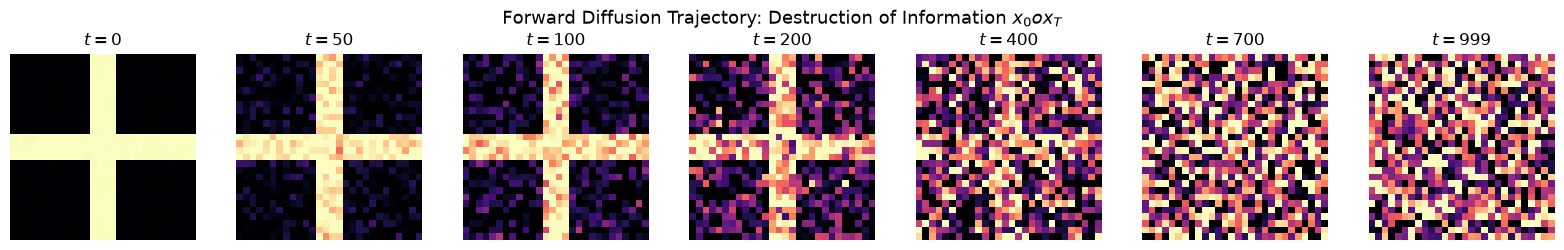

In [3]:
import importlib
solution_model = importlib.import_module("solutions.29_ddpm.model")
UNetDenoiser = solution_model.UNetDenoiser
GaussianDiffusion = solution_model.GaussianDiffusion

# Create a clean geometric target image (cross pattern)
x_clean = torch.full((1, 1, 28, 28), -1.0, device=device)
x_clean[0, 0, :, 12:16] = 1.0
x_clean[0, 0, 12:16, :] = 1.0

unet = UNetDenoiser(in_channels=1, out_channels=1, hidden_dims=(16, 32, 64), time_emb_dim=32).to(device)
diffusion = GaussianDiffusion(unet, timesteps=1000).to(device)

timesteps_to_plot = [0, 50, 100, 200, 400, 700, 999]
fig, axes = plt.subplots(1, len(timesteps_to_plot), figsize=(16, 2.5))

for idx, t_val in enumerate(timesteps_to_plot):
    t_tensor = torch.tensor([t_val], device=device, dtype=torch.long)
    with torch.no_grad():
        x_noisy = diffusion.q_sample(x_clean, t_tensor)
    img_vis = (x_noisy[0, 0].cpu().numpy() + 1.0) / 2.0
    axes[idx].imshow(img_vis, cmap="magma", vmin=0, vmax=1)
    axes[idx].axis("off")
    axes[idx].set_title(f"$t = {t_val}$")

plt.suptitle("Forward Diffusion Trajectory: Destruction of Information $x_0 \to x_T$", fontsize=13)
plt.tight_layout()
plt.show()

---
## 2. Interactive Experiment: Training DDPM on Geometric Patterns
We train a compact diffusion model on synthetic patterns using $T=100$ timesteps.

Training DDPM denoiser on geometric dataset...
Epoch   1 | Denoising Loss (MSE): 1.1304
Epoch  20 | Denoising Loss (MSE): 0.1424
Epoch  40 | Denoising Loss (MSE): 0.1505
Epoch  60 | Denoising Loss (MSE): 0.2223
Epoch  80 | Denoising Loss (MSE): 0.0858
Epoch 100 | Denoising Loss (MSE): 0.1243


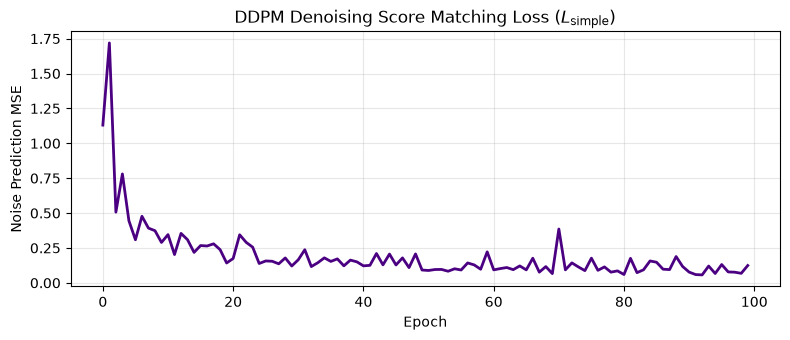

In [4]:
# Create 8 distinct 28x28 training patterns
x_train = torch.full((8, 1, 28, 28), -1.0, device=device)
x_train[0, 0, :, 12:16] = 1.0           # Vertical stripe
x_train[1, 0, 12:16, :] = 1.0           # Horizontal stripe
x_train[2, 0, 8:20, 8:20] = 1.0         # Center square
x_train[3, 0, :, :] = 0.0               # Neutral gray
x_train[4, 0, :14, :14] = 1.0           # Top-left quad
x_train[5, 0, 14:, 14:] = 1.0           # Bottom-right quad
x_train[6, 0] = torch.linspace(-1, 1, 28).unsqueeze(0).repeat(28, 1)  # Gradient H
x_train[7, 0] = torch.linspace(-1, 1, 28).unsqueeze(1).repeat(1, 28)  # Gradient V

unet = UNetDenoiser(in_channels=1, out_channels=1, hidden_dims=(32, 64, 128), time_emb_dim=64).to(device)
diffusion = GaussianDiffusion(unet, timesteps=100).to(device)
optimizer = optim.Adam(unet.parameters(), lr=3e-3)

losses = []
print("Training DDPM denoiser on geometric dataset...")
for epoch in range(1, 101):
    optimizer.zero_grad()
    loss = diffusion.compute_loss(x_train)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

    if epoch % 20 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d} | Denoising Loss (MSE): {loss.item():.4f}")

plt.figure(figsize=(8, 3.5))
plt.plot(losses, color="indigo", lw=2)
plt.title("DDPM Denoising Score Matching Loss ($L_{\\text{simple}}$)")
plt.xlabel("Epoch")
plt.ylabel("Noise Prediction MSE")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## 3. Reverse Denoising Sampling ($x_T \to x_0$)
Watch the model reconstruct sharp geometric patterns from pure white noise!

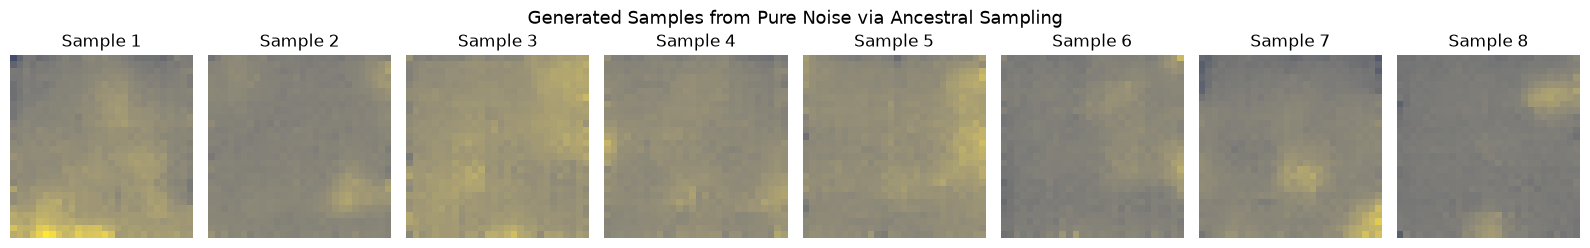

In [5]:
diffusion.eval()
with torch.no_grad():
    samples = diffusion.sample(shape=(8, 1, 28, 28), device=device)
    samples_vis = (samples.clamp(-1.0, 1.0) + 1.0) / 2.0

fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
for i in range(8):
    axes[i].imshow(samples_vis[i, 0].cpu().numpy(), cmap="cividis", vmin=0, vmax=1)
    axes[i].axis("off")
    axes[i].set_title(f"Sample {i+1}")

plt.suptitle("Generated Samples from Pure Noise via Ancestral Sampling", fontsize=13)
plt.tight_layout()
plt.show()